# Tropical Cyclone Wind Forecasting: Data, Experiments, and Error Analysis

This notebook replaces the original long-form experimentation notebook. Reusable preprocessing, modeling, and analysis functions live in `src/`; cells organize the study and display measured results.

**Question:** using observations available through time t, can we forecast wind at t+6h, t+12h, and t+24h better than persistence?

**Scope of this run:** refit development-selected models with frozen parameters, verify the published metrics, and analyze errors. There is no new model search or tuning on the inspected holdout. The data contains multiple time series, one per storm; it is not financial data.

In [1]:
%matplotlib inline
from pathlib import Path
import json
import sys

ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "src").is_dir(), "Open this notebook from the project folder"
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.data import load_observations
from src.features import feature_frame, attach_targets
from src.analysis import reproduce_selected, error_slices, plot_diagnostics, plot_slices

pd.set_option("display.max_columns", 14)
config = json.loads((ROOT / "configs/research.json").read_text())
selection = pd.read_csv(ROOT / "reports/benchmark/selection.csv")
published = pd.read_csv(ROOT / "reports/benchmark/holdout_metrics.csv")
OUTPUT = ROOT / "reports/analysis"
OUTPUT.mkdir(parents=True, exist_ok=True)

## 1. Dataset and data quality

The CSV combines cyclone records with ERA5 environmental fields. The target is observed cyclone wind speed, not an ERA5 wind column. Timestamps are interpreted as UTC following the original project; original provider responses are unavailable for independent verification.

Equivalent duplicates and conflicting observations require different treatment. Keep one equivalent observation; remove an unresolved storm/timestamp key if its records disagree instead of arbitrarily selecting a label.

In [2]:
observations, audit = load_observations(ROOT / "data/raw/dataset.csv")
quality = pd.DataFrame({"value": {
    key: audit[key] for key in ["input_rows", "removed_equivalent_observations",
    "conflicting_keys", "conflicting_rows_removed", "clean_rows", "storms"]
}})
missing = observations.isna().mean().mul(100).sort_values(ascending=False)
display(quality)
display(missing[missing > 0].rename("missing_percent").to_frame().round(2))

,value
input_rows,16485
removed_equivalent_observations,1111
conflicting_keys,3
conflicting_rows_removed,6
clean_rows,15368
storms,563


,missing_percent
pt_pressureMB,61.96
ERA5_SST,14.28
pt_moveDirectionDEG,3.18
pt_moveSpeedMPS,3.09
ERA5_u_850,0.18
ERA5_z_850,0.18
ERA5_r_850,0.18
ERA5_w_850,0.18
ERA5_vo_850,0.18
ERA5_u_500,0.18


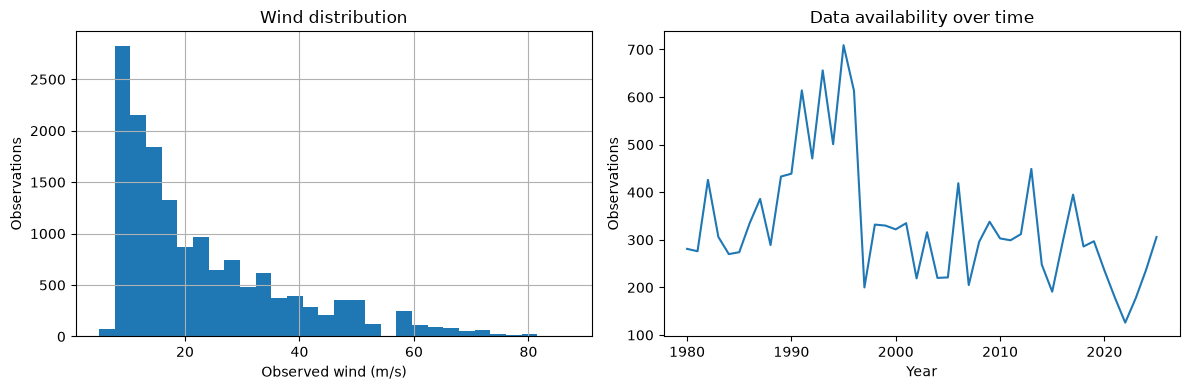

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
observations["pt_windSpeedMPS"].hist(bins=30, ax=axes[0])
axes[0].set(xlabel="Observed wind (m/s)", ylabel="Observations", title="Wind distribution")
observations.groupby(observations.timestamp.dt.year).size().plot(ax=axes[1])
axes[1].set(xlabel="Year", ylabel="Observations", title="Data availability over time")
fig.tight_layout()
plt.show()

## 2. Inputs, future targets, and storm boundaries

Inputs use information at or before t. Each target is joined within the same storm at the **exact** time t+h. The next row is not assumed to be six hours later.

Four observations at t, t-6h, t-12h, and t-18h span 18 hours. Histories never cross storm boundaries, and missing times are not filled using future observations. Imputation and scaling are fitted on each training partition only.

In [4]:
features, feature_names, sequence_names = feature_frame(observations, config["history_hours"])
example = attach_targets(observations, features, 6)
display(example[["storm_id", "timestamp", "history_start", "target_time",
                 "pt_windSpeedMPS", "target"]].head(6))
display(pd.DataFrame({"feature": feature_names}).head(18))

,storm_id,timestamp,history_start,target_time,pt_windSpeedMPS,target
0,1980-WP-01,1980-03-18 18:00:00+00:00,1980-03-18 00:00:00+00:00,1980-03-19 00:00:00+00:00,10,10.0
1,1980-WP-01,1980-03-19 00:00:00+00:00,1980-03-18 06:00:00+00:00,1980-03-19 06:00:00+00:00,10,10.0
2,1980-WP-01,1980-03-19 06:00:00+00:00,1980-03-18 12:00:00+00:00,1980-03-19 12:00:00+00:00,10,10.0
3,1980-WP-01,1980-03-19 12:00:00+00:00,1980-03-18 18:00:00+00:00,1980-03-19 18:00:00+00:00,10,10.0
4,1980-WP-01,1980-03-19 18:00:00+00:00,1980-03-19 00:00:00+00:00,1980-03-20 00:00:00+00:00,10,13.0
5,1980-WP-01,1980-03-20 00:00:00+00:00,1980-03-19 06:00:00+00:00,1980-03-20 06:00:00+00:00,13,13.0


,feature
0,pt_windSpeedMPS
1,pt_lat
2,pt_lon
3,pt_pressureMB
4,pt_moveSpeedMPS
5,pt_moveDirectionDEG
6,ERA5_u_850
7,ERA5_v_850
8,ERA5_z_850
9,ERA5_r_850


## 3. Refit the selected models

Development data before 2019 selects models; 2019-2021 calibrates intervals; 2022-2025 is the final test period. Development validation uses expanding calendar windows and disjoint storm IDs.

The next cell keeps the model families and parameters already selected from development. It does not rerun the seven-family search. The LSTM benchmark uses a separate sequence-variable subset, so the original comparison is not an architecture-only experiment.

In [5]:
display(selection.loc[selection.is_champion,
                      ["horizon_hours", "model", "cv_mae_mps", "parameters"]])
summary, predictions, partitions, elapsed_seconds = reproduce_selected(
    observations, config, selection
)
expected = published.loc[published.is_champion].set_index("horizon_hours")
for row in summary.itertuples():
    for metric in ["mae_mps", "rmse_mps", "r2", "interval_coverage"]:
        np.testing.assert_allclose(getattr(row, metric), expected.loc[row.horizon_hours, metric], atol=1e-10)
display(partitions)
display(summary[["horizon_hours", "samples", "mae_mps", "rmse_mps", "r2",
                 "mae_skill_vs_persistence", "interval_coverage"]].round(4))
display(pd.Series({"refit_seconds_including_preparation": elapsed_seconds}).to_frame("value"))

,horizon_hours,model,cv_mae_mps,parameters
4,6,hist_gradient_boosting,1.943831,"{""l2_regularization"": 5.0, ""learning_rate"": 0...."
11,12,hist_gradient_boosting,3.148619,"{""l2_regularization"": 5.0, ""learning_rate"": 0...."
18,24,hist_gradient_boosting,5.286670,"{""l2_regularization"": 5.0, ""learning_rate"": 0...."


,horizon_hours,partition,samples,storms
0,6,development,11849,476
1,6,calibration,536,34
2,6,test,643,38
3,12,development,11371,475
4,12,calibration,502,32
5,12,test,606,36
6,24,development,10419,468
7,24,calibration,444,28
8,24,test,538,36


,horizon_hours,samples,mae_mps,rmse_mps,r2,mae_skill_vs_persistence,interval_coverage
0,6,643,2.4575,3.5632,0.9485,0.2083,0.8212
1,12,606,4.2161,5.8906,0.8611,0.2683,0.8317
2,24,538,7.2201,9.6345,0.6453,0.2869,0.8086


,value
refit_seconds_including_preparation,1.732911


## 4. Look beyond the average error

Points far from the scatter plot's diagonal have larger prediction errors. Residuals are defined as prediction minus observation: negative values indicate underprediction.

These are descriptive diagnostics after inspecting the holdout. They must not be used to tune parameters and then describe the same test set as independent validation.

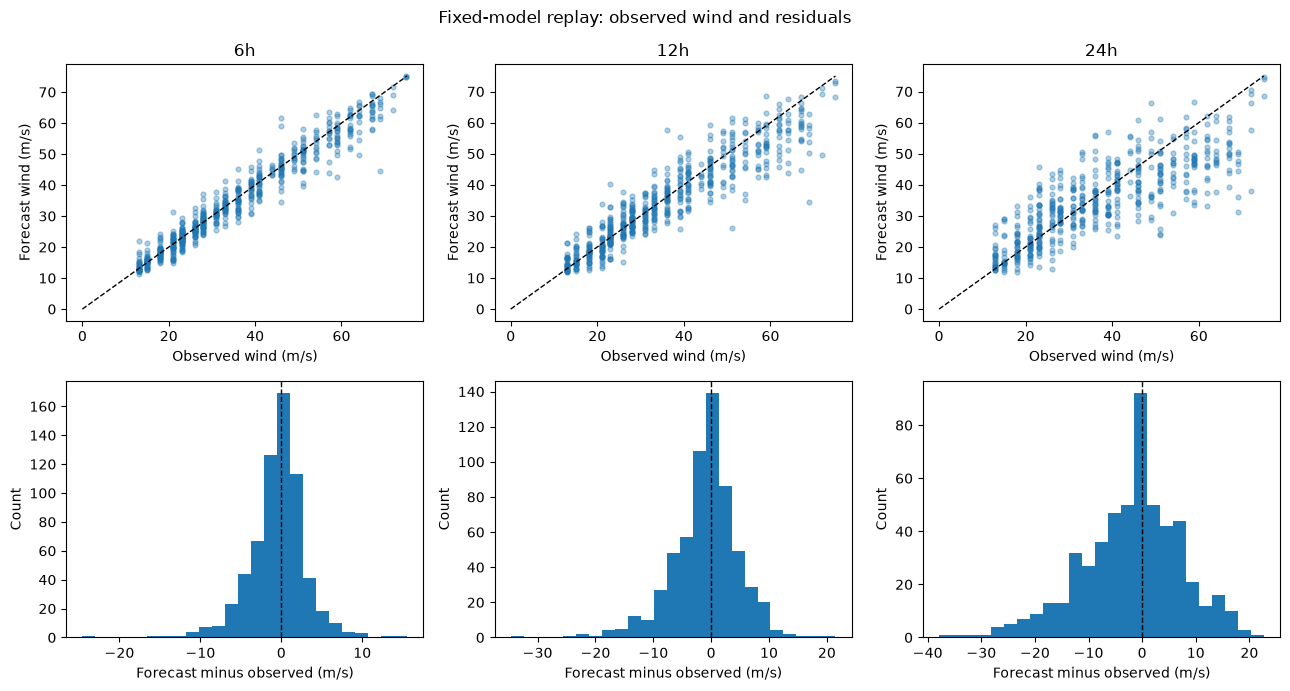

,horizon_hours,group,slice,samples,storms,model_mae_mps,persistence_mae_mps,skill_vs_persistence,bias_mps,interval_coverage
0,6,wind_band,"[0,17)",68,21,1.391,1.809,0.231,0.653,0.941
1,6,wind_band,"[17,33)",270,34,1.878,2.252,0.166,0.094,0.885
2,6,wind_band,"[33,50)",174,27,2.753,4.121,0.332,-0.187,0.787
3,6,wind_band,"[50,inf)",131,13,3.813,4.183,0.089,-2.414,0.672
4,12,wind_band,"[0,17)",60,19,2.226,3.533,0.370,1.534,0.933
5,12,wind_band,"[17,33)",242,34,3.004,4.021,0.253,0.398,0.942
6,12,wind_band,"[33,50)",173,27,4.368,7.405,0.410,-0.310,0.792
7,12,wind_band,"[50,inf)",131,13,7.166,7.832,0.085,-5.743,0.634
8,24,wind_band,"[0,17)",46,18,3.902,7.174,0.456,3.420,0.891
9,24,wind_band,"[17,33)",198,29,5.212,7.242,0.280,2.643,0.914


In [6]:
figure = plot_diagnostics(predictions)
figure.savefig(OUTPUT / "residuals.png", dpi=140)
plt.show()
slices = error_slices(predictions)
display(slices.loc[slices.group == "wind_band"].round(3))

## 5. Errors when wind changes slowly or rapidly

Stratifying by absolute future-minus-current wind uses realized outcomes for diagnosis. **Future change magnitude is not an input feature.** The 5/10 m/s cutoffs and wind-strength bins are fixed descriptive choices, not official cyclone classifications.

When persistence error is very small, relative skill can become strongly negative. Always read it alongside absolute MAE, sample counts, and storm counts.

,horizon_hours,group,slice,samples,storms,model_mae_mps,persistence_mae_mps,skill_vs_persistence,bias_mps,interval_coverage
12,6,change_band,"[0,5)",446,38,1.685,1.379,-0.222,-0.229,0.917
13,6,change_band,"[5,10)",164,31,3.319,5.756,0.423,-0.745,0.695
14,6,change_band,"[10,inf)",33,16,8.616,13.242,0.349,-1.662,0.152
15,12,change_band,"[0,5)",259,36,3.276,1.564,-1.095,-0.740,0.919
16,12,change_band,"[5,10)",225,34,3.543,6.009,0.410,-1.027,0.871
17,12,change_band,"[10,inf)",122,22,7.453,14.221,0.476,-1.598,0.574
18,24,change_band,"[0,5)",144,33,5.818,1.583,-2.674,-0.437,0.868
19,24,change_band,"[5,10)",146,32,6.647,6.432,-0.034,-1.738,0.836
20,24,change_band,"[10,inf)",248,26,8.372,17.258,0.515,-3.088,0.758


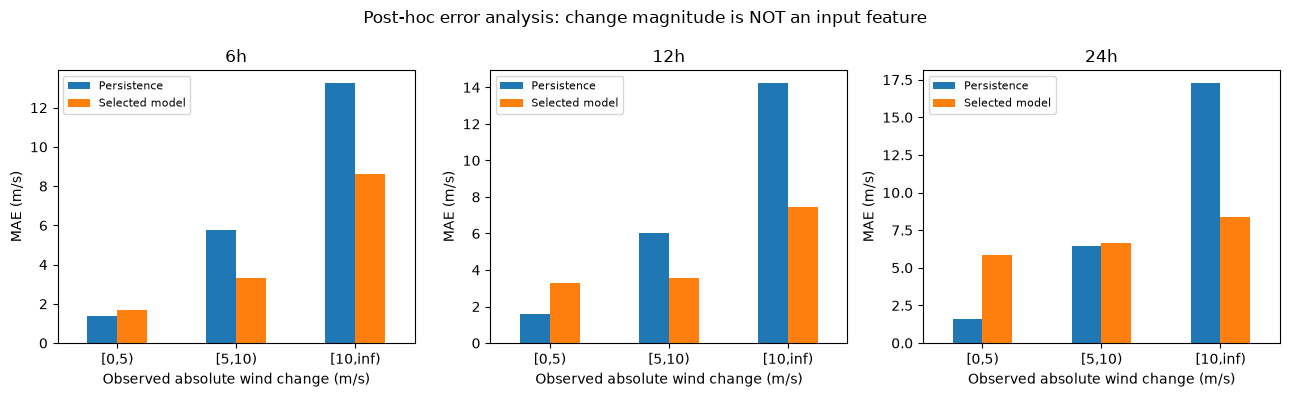

In [7]:
display(slices.loc[slices.group == "change_band"].round(3))
figure = plot_slices(slices)
figure.savefig(OUTPUT / "change_magnitude.png", dpi=140)
plt.show()

## 6. Does performance vary across years?

Each year contains a different number of observations and storms. Yearly slices can reveal instability, but they do not establish that drift caused the errors. Avoid causal conclusions from a few small groups.

,horizon_hours,group,slice,samples,storms,model_mae_mps,persistence_mae_mps,skill_vs_persistence,bias_mps,interval_coverage
21,6,year,2022,95,6,2.307,3.105,0.257,-0.242,0.874
22,6,year,2023,150,6,2.890,3.607,0.199,-0.939,0.753
23,6,year,2024,159,10,2.583,3.403,0.241,-0.497,0.824
24,6,year,2025,239,16,2.162,2.590,0.165,-0.151,0.841
25,12,year,2022,89,6,3.931,5.978,0.342,-0.375,0.865
26,12,year,2023,144,6,5.153,6.479,0.205,-2.606,0.743
27,12,year,2024,150,9,4.290,6.647,0.355,-1.232,0.807
28,12,year,2025,223,15,3.675,4.619,0.204,-0.108,0.892
29,24,year,2022,77,6,6.233,10.286,0.394,-0.284,0.896
30,24,year,2023,132,6,8.525,10.932,0.220,-6.174,0.742


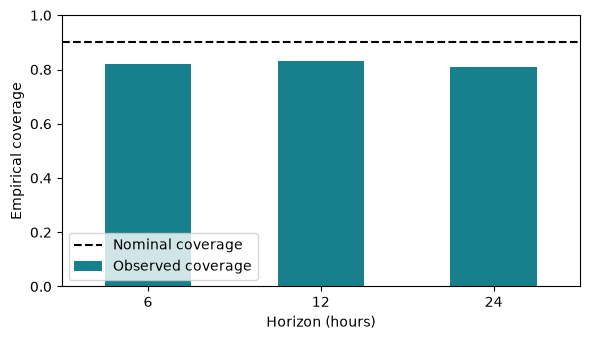

In [8]:
display(slices.loc[slices.group == "year"].round(3))
coverage = summary.set_index("horizon_hours")["interval_coverage"]
figure, axis = plt.subplots(figsize=(6, 3.5))
coverage.rename("Observed coverage").plot.bar(ax=axis, rot=0, color="#187f8c")
axis.axhline(1-config["prediction_interval_alpha"], color="black", linestyle="--", label="Nominal coverage")
axis.set(xlabel="Horizon (hours)", ylabel="Empirical coverage", ylim=(0, 1))
axis.legend()
figure.tight_layout()
figure.savefig(OUTPUT / "coverage.png", dpi=140)
plt.show()

## 7. Does feature engineering help?

More features are not automatically better. The existing ablations remove ERA5 or past-history features on development while retaining the selected hyperparameters. They measure sensitivity of these fixed configurations, not the universally best feature groups for every model.

In [9]:
ablations = pd.read_csv(ROOT / "reports/benchmark/development_ablations.csv")
display(ablations.round(4))
summary.drop(columns="fit_predict_seconds").to_csv(OUTPUT / "refit_metrics.csv", index=False)
slices.to_csv(OUTPUT / "error_slices.csv", index=False)

,horizon_hours,model,ablation,cv_mae_mps,delta_vs_full_mps
0,6,hist_gradient_boosting,without_era5,2.0004,0.0566
1,6,hist_gradient_boosting,without_past_lags,2.0829,0.1391
2,12,hist_gradient_boosting,without_era5,3.2222,0.0736
3,12,hist_gradient_boosting,without_past_lags,3.3833,0.2347
4,24,hist_gradient_boosting,without_era5,5.5331,0.2465
5,24,hist_gradient_boosting,without_past_lags,5.6159,0.3292


## Findings from this run

- For realized wind speeds of at least 50 m/s, the 24h forecast has **12.26 m/s MAE**, **-11.79 m/s bias**, and **55.3% coverage** across 132 samples. Overall averages conceal substantial underprediction in this group.
- Persistence outperforms the selected model when realized wind changes by less than 5 m/s. This outcome-defined group is diagnostic, not a rule available before observing the future.
- When realized change is at least 10 m/s, the 24h model reduces MAE from **17.26 to 8.37 m/s** across 248 samples, while still making substantial errors.
- In this sample, 2023 has higher MAE than the other years at all horizons. The tables do not identify a specific causal weather factor or prove a drift mechanism.

These are descriptions of an already inspected test set, not an independent new validation round. Underprediction and insufficient interval coverage remain unresolved. New remedies should be evaluated on development before confirmation on another untouched dataset.

## 8. Turning evidence into an interview discussion

Choose an **observed problem** and explain the evidence and response:

1. **Inconsistent target definitions:** the original ML branch predicted the contemporaneous label, while DL predicted a later row. The extension aligns future targets at exact horizons and evaluates common origins.
2. **Duplicates, conflicts, and irregular time gaps:** audit before generating lags; discard unresolved conflicts, use exact-clock joins, and test storm boundaries and future-information isolation.
3. **Average metrics hide failures:** compare persistence and examine residuals and slices by wind strength, realized change, and year.
4. **Interval coverage misses its nominal level:** report the shortfall rather than claiming calibration drift is solved or a live warning system is ready.

Distinguish work done during the original project from findings and fixes made in this later extension. Do not describe a new discovery as something resolved years earlier. A credible research discussion needs a genuine problem, evidence, and an honest account of what remains open.